# AYATSK: the Yager T-norm and the lower bound of the membership function

This notebook follows, one step at a time, the classifier of

> G. Xue, Y. Yang and J. Wang, "Adaptive Yager T-norm-based Takagi-Sugeno-Kang fuzzy
> systems", *IEEE Transactions on Systems, Man, and Cybernetics: Systems*, 2025.

on Wdbc, one of the datasets of the article. AYATSK computes the firing strength of a
rule with the Yager T-norm, whose parameter is set from the number of features, and uses
a membership function that never falls below $1/K$. The notebook is a short version of
the script `examples/reproductions/ayatsk_2025.py`, which runs two datasets with ten folds
repeated five times; here one repetition on one dataset runs in about a minute.

1. settings and reproducibility;
2. the data;
3. the membership function and its lower bound;
4. a fit with each value of K;
5. what the fitted model looks like;
6. ten folds, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler

import highfis
from highfis import AYATSKClassifier

In [2]:
SEED = 0
FOLDS = 10
THREADS = 4

# Table III of the article, Wdbc: mean test accuracy in percent, by K.
ARTICLE = {10: 95.11, 2: 96.69}

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Wdbc has 569 samples of breast masses, benign or malignant, described by 30 features.

In [3]:
features, labels = load_breast_cancer(return_X_y=True)
features = features.astype(np.float32)

print(f"{features.shape[0]} samples, {features.shape[1]} features")
print(f"samples per class: {np.bincount(labels).tolist()}")

569 samples, 30 features
samples per class: [212, 357]


The first of ten folds is followed in detail. The article scales the inputs to [0, 1],
with the range of the training part.

In [4]:
folds = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
train, test = next(folds.split(features, labels))

scaler = MinMaxScaler().fit(features[train])
x_train, x_test = scaler.transform(features[train]), scaler.transform(features[test])
y_train, y_test = labels[train], labels[test]

print(f"training: {len(x_train)} samples, test: {len(x_test)} samples")

training: 512 samples, test: 57 samples


## 3. The membership function and its lower bound

The membership function of the article is $K^{-1 + \exp(-(x - m)^2 / 2\sigma^2)}$: it
equals one at the centre and tends to $1/K$ far from it, instead of zero. With a degree
that cannot vanish, no single feature can switch a rule off, which is what makes the
T-norm usable with many features.

The same fuzzy set for the two values of K that the notebook uses:

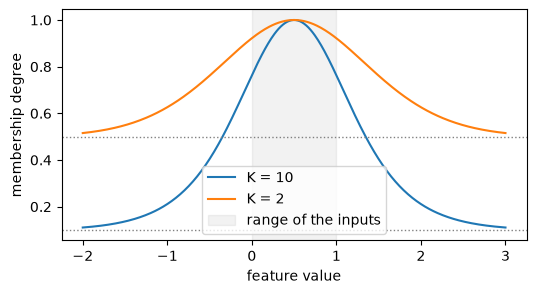

In [5]:
x = np.linspace(-2, 3, 400)
fig, ax = plt.subplots(figsize=(6, 3))
for k in (10, 2):
    ax.plot(x, k ** (-1 + np.exp(-((x - 0.5) ** 2) / 2)), label=f"K = {k}")
    ax.axhline(1 / k, color="gray", linestyle=":", linewidth=1)
ax.axvspan(0, 1, color="gray", alpha=0.1, label="range of the inputs")
ax.set_xlabel("feature value")
ax.set_ylabel("membership degree")
ax.legend()
plt.show()

On inputs in [0, 1] with spreads of one, the degrees stay in a narrow band near one.
The article finds no value of K that is the best on every dataset; the default of
`AYATSKClassifier` is `k=2`, the value with the best mean in its Table III.

## 4. A fit with each value of K

Three rules with centres at 0, 0.5 and 1, Adam on the whole training set for 300 epochs,
and a learning rate of 0.01: the setting of the article for low-dimensional data, and the
defaults of the estimator.

In [6]:
models = {}
for k in ARTICLE:
    models[k] = AYATSKClassifier(k=float(k), learning_rate=0.01, random_state=SEED).fit(x_train, y_train)
    print(
        f"K = {k:2d}: training {100 * models[k].score(x_train, y_train):.1f}%, "
        f"test {100 * models[k].score(x_test, y_test):.1f}%"
    )

K = 10: training 97.3%, test 96.5%


K =  2: training 97.3%, test 94.7%


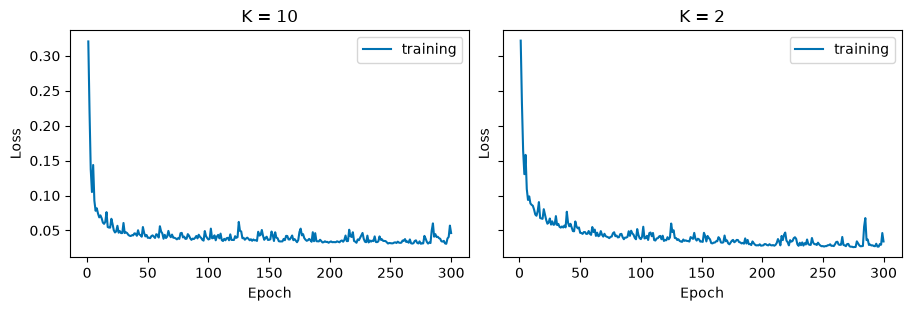

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True, layout="constrained")
for ax, (k, fitted) in zip(axes, models.items()):
    fitted.plot_history(ax=ax)
    ax.set_title(f"K = {k}")
plt.show()

## 5. What the fitted model looks like

The model with K = 2. Its confusion matrix on the 57 test samples, and the margin of each
decision:

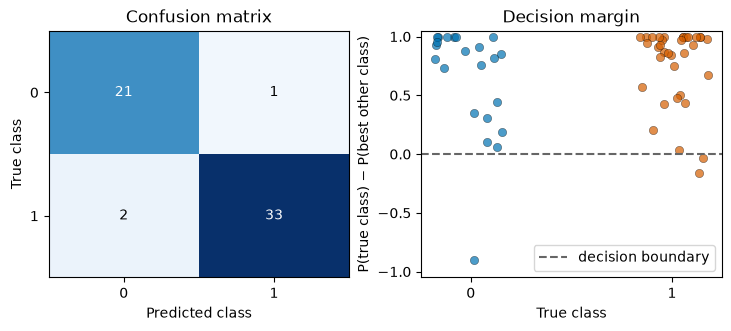

In [8]:
model = models[2]
model.plot_diagnostics(x_test, y_test)

The fuzzy sets after training, for four of the features:

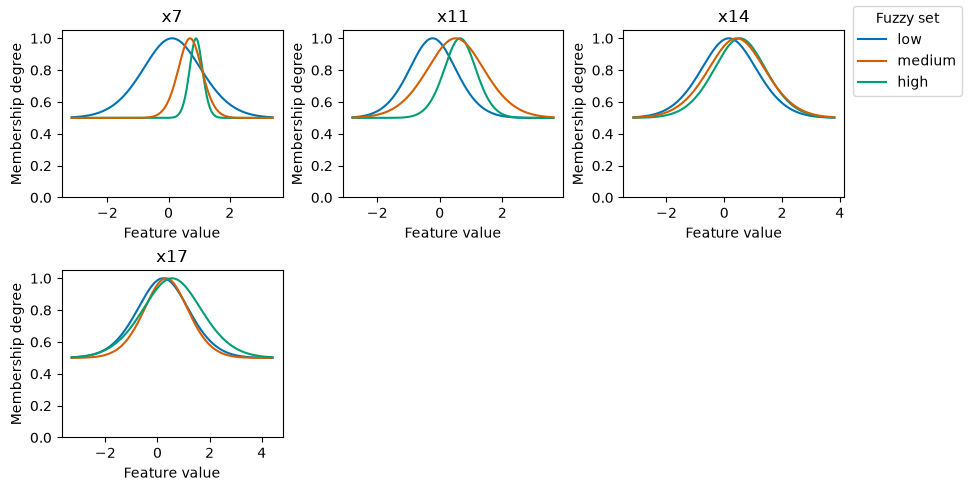

In [9]:
model.plot_memberships(max_features=4)

How the three rules share the samples of each class, for the two values of K:

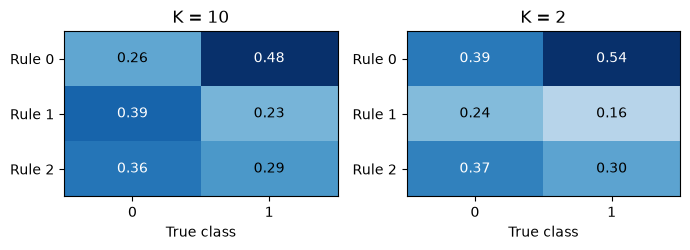

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6))
for ax, (k, fitted) in zip(axes, models.items()):
    fitted.plot_rule_activation(x_test, y_test, ax=ax)
    ax.set_title(f"K = {k}")
plt.tight_layout()
plt.show()

A summary of the model and of its training, in one call:

In [11]:
model.summary()

AYATSKClassifier
  task               classification, 2 classes
  features           30 seen in fit, 30 used by the model
  rules              3 (rule base: coco)
  fuzzy sets         3 per feature, CompositeExponentialMF
  firing strength    RuleLayer, T-norm YagerTNorm
  defuzzifier        SumBasedDefuzzifier
  consequents        ClassificationConsequentLayer
  parameters         366 trainable (180 antecedent, 186 consequent)
Training (batch size 51)
  phase     epochs  rate  loss first -> last  accuracy
  training     300  0.01    0.3217 -> 0.0343    0.9727

How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [12]:
model.explain(x_test[0])

Prediction: 0
Output, the sum of the contributions of the 3 rules: 0: +0.88, 1: +0.12
Rule 0, weight 0.40: contributes 0: -0.59, 1: +0.99
    IF x12 is medium AND x15 is medium AND x20 is medium AND x22 is medium
       AND the other 26 features are low
Rule 2, weight 0.38: contributes 0: +2.04, 1: -1.65
    IF x2 is medium AND x5 is medium AND x6 is medium AND x7 is medium
       AND x8 is medium AND x10 is medium AND x11 is medium AND x13 is medium
       AND x14 is medium AND x15 is low AND x21 is medium AND x23 is medium
       AND x24 is medium AND x28 is medium AND the other 16 features are high
Rule 1, weight 0.22: contributes 0: -0.57, 1: +0.78
    IF x1 is medium AND x2 is high AND x3 is medium AND x4 is medium
       AND x5 is high AND x6 is high AND x7 is high AND x8 is high
       AND x9 is medium AND x10 is high AND x11 is high AND x12 is low
       AND x13 is high AND x14 is high AND x15 is high AND x16 is medium
       AND x17 is medium AND x18 is medium AND x19 is mediu

How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [13]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.88, median 0.96
test part:     min 0.91, median 0.96


## 6. Ten folds, next to the article

In [14]:
results = {f"K = {k}": [] for k in ARTICLE}

for train, test in StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=SEED).split(features, labels):
    scaler = MinMaxScaler().fit(features[train])
    a_train, a_test = scaler.transform(features[train]), scaler.transform(features[test])
    for k in ARTICLE:
        fitted = AYATSKClassifier(k=float(k), learning_rate=0.01, random_state=SEED).fit(a_train, labels[train])
        results[f"K = {k}"].append(100 * fitted.score(a_test, labels[test]))

print(f"{'K':>6s} {'article':>8s} {'highFIS':>8s} {'std':>6s}")
for k in ARTICLE:
    scores = results[f"K = {k}"]
    print(f"{k:6d} {ARTICLE[k]:8.2f} {np.mean(scores):8.2f} {np.std(scores):6.2f}")

     K  article  highFIS    std
    10    95.11    97.18   1.62
     2    96.69    96.13   2.04


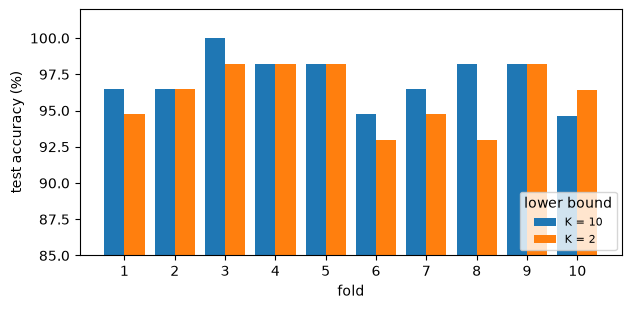

In [15]:
LOWER, LEGEND = 85, "lower bound"

fold_means = {label: np.asarray(scores) for label, scores in results.items()}

fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.8 / len(fold_means)
for position, (label, scores) in enumerate(fold_means.items()):
    ax.bar(np.arange(FOLDS) + (position - (len(fold_means) - 1) / 2) * width, scores, width=width, label=str(label))
ax.set_xticks(np.arange(FOLDS), [str(fold + 1) for fold in range(FOLDS)])
ax.set_xlabel("fold")
ax.set_ylabel("test accuracy (%)")
ax.set_ylim(LOWER, 102)
ax.legend(loc="lower right", fontsize=8, title=LEGEND)
plt.show()

The script repeats the ten folds five times, as the article does, and also runs Wine.